# Task 2: Real Estate Housing Price Prediction

## OLS, Ridge (L2), Lasso (L1) and XGBoost Benchmark

**Datheon Machine Learning & Data Science Internship**

### Project goal

Predict California district median house values from demographic, housing and location features. This notebook follows a leakage-aware machine-learning workflow and compares:

- Ordinary Least Squares (OLS) using `LinearRegression`
- Ridge regression using L2 regularisation
- Lasso regression using L1 regularisation

OLS, Ridge and Lasso are the required linear models. A tuned XGBoost regressor is added as a nonlinear performance benchmark. All models are compared using **RMSE**, **MAE** and **R²**; selection is based on training cross-validation RMSE, with one final evaluation on the held-out test set.

### Learning outcomes

By completing this notebook, you will practise data inspection, exploratory analysis, missing-value imputation, categorical encoding, feature engineering, standardisation, multicollinearity diagnostics, cross-validation, hyperparameter tuning and residual analysis.

> **Important:** The supplied `Task 2-Housing.csv` is loaded from the project folder. The California Housing target is capped at $500,001; report this limitation when interpreting predictions.


## 1. Import libraries and configure the project

We use:

- **Pandas / NumPy** for data handling and numerical operations.
- **Matplotlib / Seaborn** for static visualisations.
- **Scikit-learn** for preprocessing, regression, cross-validation and metrics.
- **Statsmodels** optionally for Variance Inflation Factor (VIF).

The notebook uses a fixed random seed so that the train/test split and results are reproducible. A test set is held back until final evaluation; model selection is performed using cross-validation on the training set only.


In [1]:
# If a required library is missing, install it in your active environment from Terminal:
# python3 -m pip install pandas numpy matplotlib seaborn scikit-learn jupyter ipykernel statsmodels plotly

from pathlib import Path
import joblib
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV, KFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from xgboost import XGBRegressor
from housing_features import add_engineered_features
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")

print("Libraries imported successfully.")
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("XGBoost: imported successfully")


Libraries imported successfully.
Pandas: 3.1.1
NumPy: 2.5.5
XGBoost: imported successfully


The required data science and regression packages imported successfully, including XGBoost for the optional nonlinear comparison. The fixed random seed supports reproducible splitting and model search. **Observed result:** pandas, NumPy, and XGBoost are available in the active environment.


## 2. Load the California Housing dataset

The dataset contains California census-block-group observations. Each row describes a district, not an individual house. The target, `median_house_value`, is expressed in US dollars. The original dataset caps some target values at **$500,001**, so predictions near this ceiling should be interpreted with care: the target is top-coded rather than an exact uncensored market price.


In [2]:
# Resolve the CSV relative to the notebook's working directory.
search_roots = [
    Path.cwd(),
    Path.cwd().parent,
    Path("/Users/mac/Desktop/Internship"),
]
file_names = {"task 2-housing.csv", "task_2_housing.csv", "housing.csv"}

candidate_paths = []
for root in search_roots:
    if root.is_dir():
        candidate_paths.extend(
            path for path in root.rglob("*.csv")
            if path.name.lower() in file_names
        )

candidate_paths = list(dict.fromkeys(candidate_paths))
DATA_PATH = next((path for path in candidate_paths if path.is_file()), None)

if DATA_PATH is None:
    raise FileNotFoundError(
        "Housing CSV not found. Place Task_2_Housing.csv or housing.csv in the "
        "notebook folder or one of its subfolders, or set DATA_PATH to its full path."
    )

df = pd.read_csv(DATA_PATH)
print(f"Dataset loaded from: {DATA_PATH.resolve()}")
print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]}")
display(df.head())


Dataset loaded from: /Users/mac/Desktop/Internship/Task 2-Housing.csv
Rows: 20,640 | Columns: 10


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.230,37.880,41.000,880.000,129.000,322.000,126.000,8.325,"452,600.000",NEAR BAY
1,-122.220,37.860,21.000,"7,099.000","1,106.000","2,401.000","1,138.000",8.301,"358,500.000",NEAR BAY
2,-122.240,37.850,52.000,"1,467.000",190.000,496.000,177.000,7.257,"352,100.000",NEAR BAY
3,-122.250,37.850,52.000,"1,274.000",235.000,558.000,219.000,5.643,"341,300.000",NEAR BAY
4,-122.250,37.850,52.000,"1,627.000",280.000,565.000,259.000,3.846,"342,200.000",NEAR BAY


The CSV was found in the project folder and loaded locally. The preview contains district-level features, the target `median_house_value`, and the `ocean_proximity` category. **Observed result:** 20,640 rows and 10 columns loaded from `Task 2-Housing.csv`.


## 3. Initial data inspection

We inspect the structure, data types, descriptive statistics, duplicate rows and missing values before making preprocessing decisions. A missing value in `total_bedrooms` is expected in this version of the dataset. We will not delete those rows; instead, the median imputer will learn the replacement value from the training data only.


In [3]:
print("Dataset dimensions:", df.shape)
print("\nColumn data types:")
display(df.dtypes.to_frame("data_type"))

print("\nDataset information:")
df.info()

print("\nDescriptive statistics:")
display(df.describe(include="all").T)

print("\nMissing values by column:")
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2)
}).sort_values("missing_count", ascending=False)
display(missing_summary)

print("\nDuplicate rows:", df.duplicated().sum())


Dataset dimensions: (20640, 10)

Column data types:


,data_type
longitude,float64
latitude,float64
housing_median_age,float64
total_rooms,float64
total_bedrooms,float64
population,float64
households,float64
median_income,float64
median_house_value,float64
ocean_proximity,str



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB

Descriptive statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
longitude,"20,640.000",NaN,NaN,NaN,-119.570,2.004,-124.350,-121.800,-118.490,-118.010,-114.310
latitude,"20,640.000",NaN,NaN,NaN,35.632,2.136,32.540,33.930,34.260,37.710,41.950
housing_median_age,"20,640.000",NaN,NaN,NaN,28.639,12.586,1.000,18.000,29.000,37.000,52.000
total_rooms,"20,640.000",NaN,NaN,NaN,"2,635.763","2,181.615",2.000,"1,447.750","2,127.000","3,148.000","39,320.000"
total_bedrooms,"20,433.000",NaN,NaN,NaN,537.871,421.385,1.000,296.000,435.000,647.000,"6,445.000"
population,"20,640.000",NaN,NaN,NaN,"1,425.477","1,132.462",3.000,787.000,"1,166.000","1,725.000","35,682.000"
households,"20,640.000",NaN,NaN,NaN,499.540,382.330,1.000,280.000,409.000,605.000,"6,082.000"
median_income,"20,640.000",NaN,NaN,NaN,3.871,1.900,0.500,2.563,3.535,4.743,15.000
median_house_value,"20,640.000",NaN,NaN,NaN,"206,855.817","115,395.616","14,999.000","119,600.000","179,700.000","264,725.000","500,001.000"
ocean_proximity,20640,5,<1H OCEAN,9136,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Missing values by column:


,missing_count,missing_percent
total_bedrooms,207,1.000
longitude,0,0.000
latitude,0,0.000
housing_median_age,0,0.000
total_rooms,0,0.000
population,0,0.000
households,0,0.000
median_income,0,0.000
median_house_value,0,0.000
ocean_proximity,0,0.000



Duplicate rows: 0


The dataset contains nine numeric columns and one categorical column. `total_bedrooms` has missing values, which the modeling pipeline will impute after the train/test split. There are no duplicate rows. **Observed result:** 20,640 observations; 207 missing `total_bedrooms` values (about 1.00%); no duplicate rows.


## 4. Complete data cleaning and missing-value treatment

This section performs a documented quality check before exploratory analysis and modelling. We preserve the original loaded data in `df_raw` so that cleaning decisions remain auditable.

Cleaning steps:

1. Standardise column names and remove leading/trailing spaces from text categories.
2. Remove exact duplicate rows.
3. Convert known invalid numeric values (for example, impossible negative counts or out-of-range coordinates) to missing values rather than silently keeping them.
4. Check target availability. Rows without a target cannot be used for supervised training, so they are removed.
5. Report missingness after rule-based cleaning.
6. Impute predictor missing values inside the training-only preprocessing pipeline in Section 9. Numeric predictors use the median; categorical predictors use the most frequent category.

**Important:** We do not automatically delete statistical outliers. Large populations, room counts or house values can be legitimate district characteristics. Outliers are investigated in EDA and retained unless they are demonstrably invalid.


In [4]:

# Keep an untouched copy for comparison and audit.
df_raw = df.copy()

# 4.1 Standardise column names and text categories.
df.columns = (
    df.columns.astype(str)
      .str.strip()
      .str.lower()
      .str.replace(r"[^a-z0-9]+", "_", regex=True)
      .str.strip("_")
)

# Identify categorical columns, including newer Pandas string dtype.
categorical_cols = df.select_dtypes(
    include=["object", "category", "str"]
).columns.tolist()

for column in categorical_cols:
    # Remove accidental whitespace; preserve genuinely missing entries.
    df[column] = df[column].map(
        lambda value: value.strip() if isinstance(value, str) else value
    )

    # Convert empty strings to missing values.
    df[column] = df[column].replace("", np.nan)

print("Column names after standardisation:")
print(df.columns.tolist())

print("\nCategorical columns:")
print(categorical_cols)


Column names after standardisation:
['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'median_house_value', 'ocean_proximity']

Categorical columns:
['ocean_proximity']


Column names and category text are normalized for reliable downstream processing. In this dataset, column names were already in the desired format, and `ocean_proximity` is the only categorical predictor. **Observed result:** 10 standardized columns, with `ocean_proximity` identified as categorical.


In [5]:
# 4.2 Remove exact duplicate observations.
duplicates_before = int(df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
duplicates_removed = duplicates_before

print(f"Exact duplicate rows found: {duplicates_before:,}")
print(f"Exact duplicate rows removed: {duplicates_removed:,}")
print("Shape after duplicate removal:", df.shape)


Exact duplicate rows found: 0


Exact duplicate rows removed: 0
Shape after duplicate removal: (20640, 10)


Exact duplicate rows are removed before analysis so repeated records do not disproportionately influence model fitting. **Observed result:** no duplicates were present; all 20,640 rows remain.


In [6]:
# 4.3 Convert invalid numeric values to NaN.
# These rules are domain checks, not statistical outlier filters.
numeric_cols_for_cleaning = df.select_dtypes(include=np.number).columns.tolist()

# Replace positive/negative infinity with missing values.
df[numeric_cols_for_cleaning] = df[numeric_cols_for_cleaning].replace(
    [np.inf, -np.inf], np.nan
)

invalid_value_counts = {}

# Count variables and household/population measures cannot be negative.
non_negative_columns = [
    "total_rooms", "total_bedrooms", "population", "households",
    "median_income", "housing_median_age", "median_house_value"
]
for column in non_negative_columns:
    if column in df.columns:
        invalid_mask = df[column] < 0
        invalid_value_counts[column] = int(invalid_mask.sum())
        df.loc[invalid_mask, column] = np.nan

# California geographic coordinates should fall within valid broad bounds.
if "longitude" in df.columns:
    invalid_mask = ~df["longitude"].between(-125, -113)
    invalid_value_counts["longitude_out_of_range"] = int(invalid_mask.sum())
    df.loc[invalid_mask, "longitude"] = np.nan

if "latitude" in df.columns:
    invalid_mask = ~df["latitude"].between(32, 43)
    invalid_value_counts["latitude_out_of_range"] = int(invalid_mask.sum())
    df.loc[invalid_mask, "latitude"] = np.nan

# A district's bedrooms should not exceed its total rooms.
if {"total_bedrooms", "total_rooms"}.issubset(df.columns):
    invalid_mask = (
        df["total_bedrooms"].notna()
        & df["total_rooms"].notna()
        & (df["total_bedrooms"] > df["total_rooms"])
    )
    invalid_value_counts["bedrooms_greater_than_rooms"] = int(invalid_mask.sum())
    df.loc[invalid_mask, "total_bedrooms"] = np.nan

print("Invalid values converted to missing values:")
display(pd.Series(invalid_value_counts, name="count").to_frame())


Invalid values converted to missing values:


,count
total_rooms,0
total_bedrooms,0
population,0
households,0
median_income,0
housing_median_age,0
median_house_value,0
longitude_out_of_range,0
latitude_out_of_range,0
bedrooms_greater_than_rooms,0


The cell checks nonnegative measurements, California coordinate bounds, and whether bedrooms exceed total rooms. Invalid values would be marked missing and imputed within the training pipeline; no observations triggered these rules **Observed result:** zero invalid values were found in every checked field.


In [7]:
# 4.4 Validate required columns and remove rows with missing target values.
required_columns = {
    "longitude", "latitude", "housing_median_age", "total_rooms",
    "total_bedrooms", "population", "households", "median_income",
    "median_house_value", "ocean_proximity"
}
missing_required_columns = required_columns.difference(df.columns)

if missing_required_columns:
    raise ValueError(
        f"Dataset is missing required columns: {sorted(missing_required_columns)}"
    )

target_missing_before = int(df["median_house_value"].isna().sum())
df = df.dropna(subset=["median_house_value"]).reset_index(drop=True)

print(f"Rows removed because target was missing: {target_missing_before:,}")
print("Shape after target validation:", df.shape)


Rows removed because target was missing: 0
Shape after target validation: (20640, 10)


The target column is required and rows without a target would be removed before modeling. No target values were missing, so the complete dataset remains available **Observed result:** zero rows removed; the cleaned dataset remains 20,640 by 10.


In [8]:
# 4.5 Produce a complete data-quality and missingness report.
cleaning_report = pd.DataFrame({
    "data_type": df.dtypes.astype(str),
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2),
    "unique_values": df.nunique(dropna=True)
}).sort_values(["missing_count", "missing_percent"], ascending=False)

print("Data quality report after rule-based cleaning:")
display(cleaning_report)

print("Remaining duplicate rows:", df.duplicated().sum())
print("Rows retained:", len(df))
print("Columns retained:", df.shape[1])

# Save the audit report so cleaning decisions are part of the deliverables.
CLEANING_OUTPUT_DIR = Path("outputs/model_results")
CLEANING_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
cleaning_report.to_csv(CLEANING_OUTPUT_DIR / "Task 2_data_cleaning_report.csv")


Data quality report after rule-based cleaning:


,data_type,missing_count,missing_percent,unique_values
total_bedrooms,float64,207,1.000,1923
longitude,float64,0,0.000,844
latitude,float64,0,0.000,862
housing_median_age,float64,0,0.000,52
total_rooms,float64,0,0.000,5926
population,float64,0,0.000,3888
households,float64,0,0.000,1815
median_income,float64,0,0.000,12928
median_house_value,float64,0,0.000,3842
ocean_proximity,str,0,0.000,5


Remaining duplicate rows: 0
Rows retained: 20640
Columns retained: 10


The report summarizes types, missingness, and distinct values after rule-based cleaning. It is also saved for reproducibility. Predictor missingness is deliberately left for fold-specific imputation rather than being filled before splitting. **Observed result:** `total_bedrooms` has 207 missing values (1.00%); no duplicates remain; 20,640 rows and 10 columns are retained. The audit CSV is saved under `outputs/model_results/Task 2_data_cleaning_report.csv`.


### How missing values are handled

We intentionally do **not** fill predictor missing values across the entire dataset at this point. Doing so before the train/test split would allow information from the test set to influence the imputation values (data leakage).

Instead, the modelling pipeline later performs:

- **Numeric predictors:** median imputation learned from each training fold.
- **Categorical predictors:** most-frequent imputation learned from each training fold.
- **Engineered ratios:** any undefined values caused by zero denominators are also treated as missing and median-imputed by the numeric pipeline.
- **Target:** rows with missing target values are removed because a supervised model cannot learn from an unknown outcome.

This approach cleans the data while keeping the evaluation honest.


## 5. Define the target and inspect the target distribution

`median_house_value` is the continuous outcome we want to predict. We inspect its distribution and key percentiles to understand skewness and the upper-value cap.


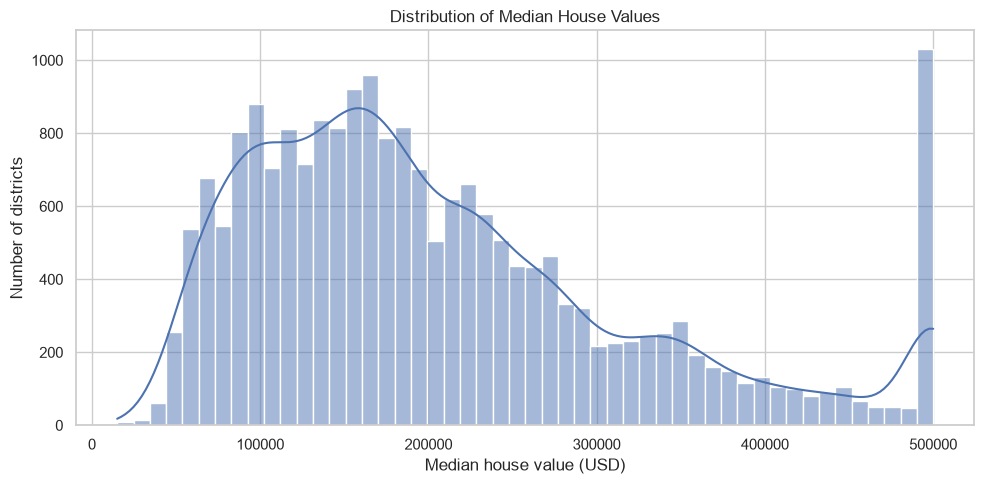

,median_house_value
count,"20,640.000"
mean,"206,855.817"
std,"115,395.616"
min,"14,999.000"
25%,"119,600.000"
50%,"179,700.000"
75%,"264,725.000"
90%,"376,600.000"
95%,"489,810.000"
99%,"500,001.000"


Share of target values at $500,001: 4.68%


In [9]:
TARGET = "median_house_value"

if TARGET not in df.columns:
    raise ValueError(f"Target column '{TARGET}' was not found.")

plt.figure(figsize=(10, 5))
sns.histplot(df[TARGET], bins=50, kde=True)
plt.title("Distribution of Median House Values")
plt.xlabel("Median house value (USD)")
plt.ylabel("Number of districts")
plt.tight_layout()
plt.show()

display(df[TARGET].describe(percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]).to_frame())
print("Share of target values at $500,001:",
      f"{(df[TARGET] == 500001).mean() * 100:.2f}%")


House values are right-skewed and the upper tail is affected by the dataset's maximum-value cap. A model cannot learn exact values above that cap from these labels. **Observed result:** mean target value is $206,855.82, median is $179,700, and maximum is $500,001. About 4.68% of labels are exactly at the $500,001 ceiling.


## 6. Exploratory data analysis (EDA)

### 5.1 Numeric feature distributions

Histograms reveal skewness and unusual ranges. Several count variables (rooms, bedrooms, population and households) are typically strongly right-skewed.


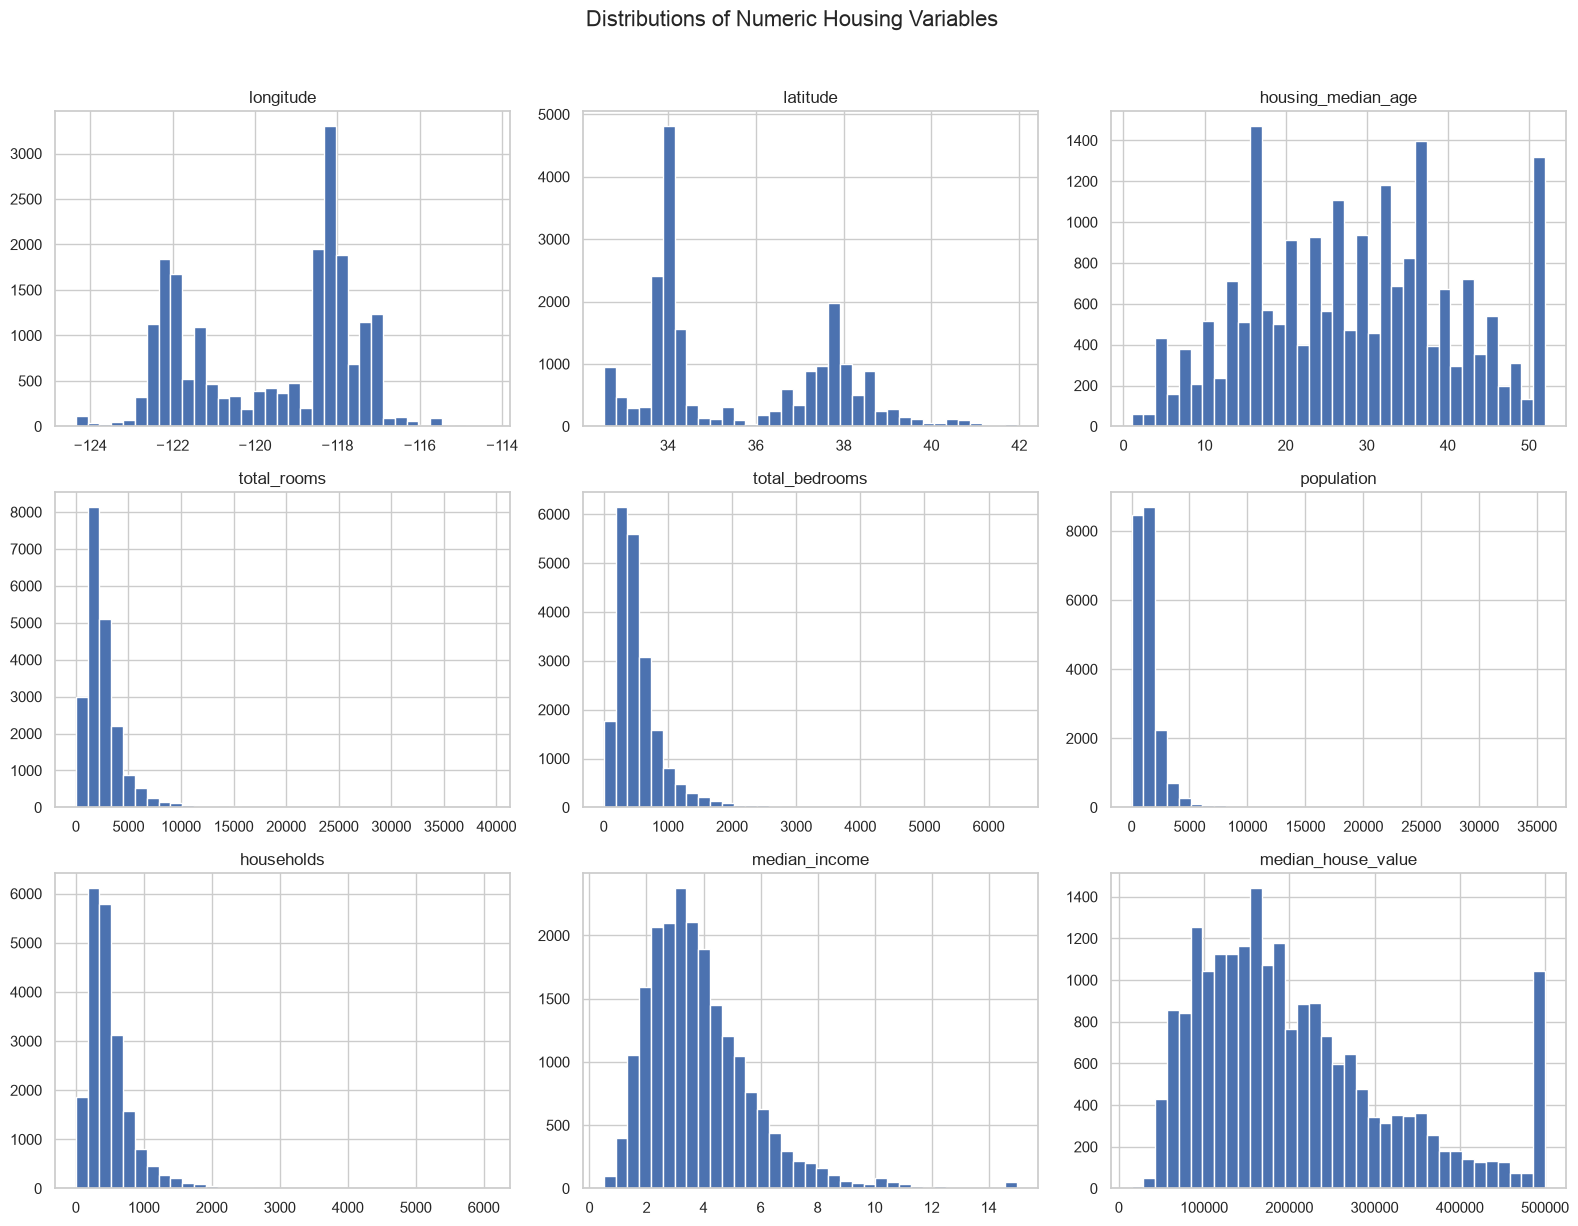

In [10]:
numeric_columns = df.select_dtypes(include=np.number).columns.tolist()
df[numeric_columns].hist(figsize=(16, 12), bins=35, edgecolor="white")
plt.suptitle("Distributions of Numeric Housing Variables", y=1.02, fontsize=16)
plt.tight_layout()
plt.show()


The histograms reveal different scales and skewness across the numeric inputs. Count variables have long upper tails, which is why the analysis retains observations but uses scaling and robust median imputation in the linear-model pipeline. The target's upper cap is also visible.


### 5.2 Boxplots for potential outliers

Boxplots help identify extreme observations. Outliers are not automatically removed: unusually large districts can be valid observations. We will retain them unless a data-quality reason justifies removal.


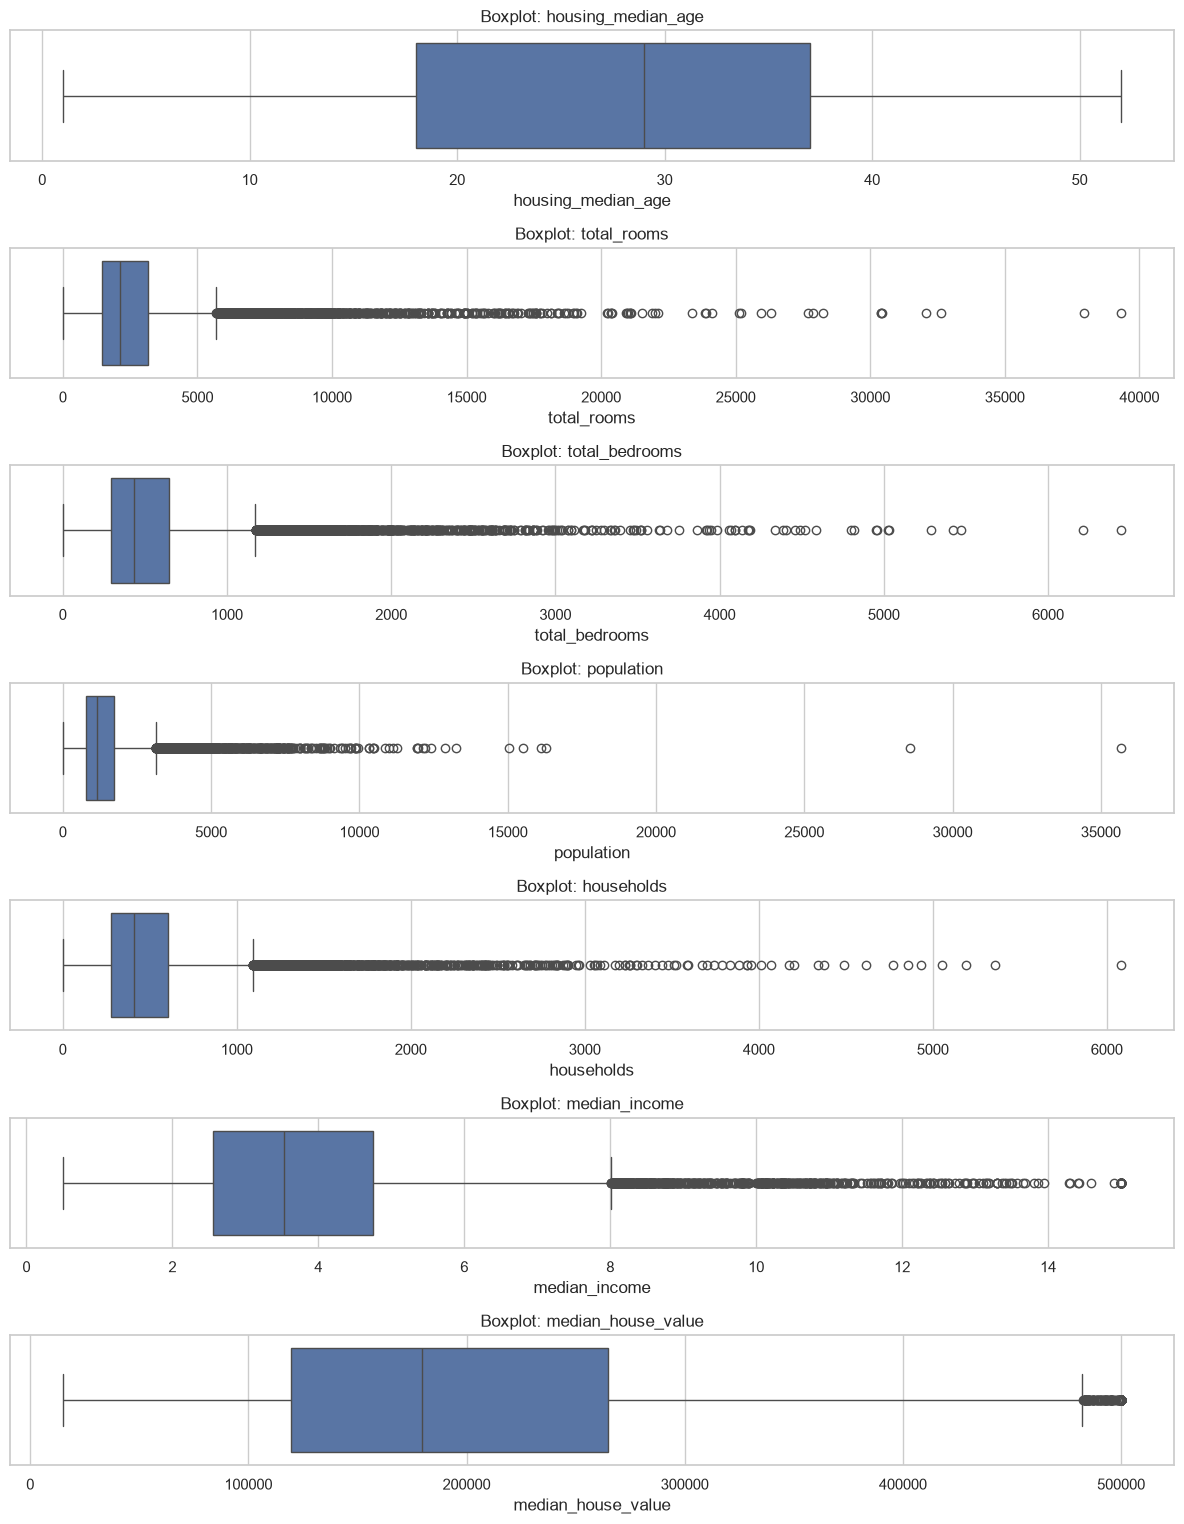

In [11]:
box_columns = [
    "housing_median_age", "total_rooms", "total_bedrooms",
    "population", "households", "median_income", TARGET
]
available_box_columns = [col for col in box_columns if col in df.columns]

fig, axes = plt.subplots(len(available_box_columns), 1,
                         figsize=(12, 2.2 * len(available_box_columns)))
if len(available_box_columns) == 1:
    axes = [axes]

for ax, col in zip(axes, available_box_columns):
    sns.boxplot(x=df[col], ax=ax)
    ax.set_title(f"Boxplot: {col}")
plt.tight_layout()
plt.show()


The boxplots expose skew and extreme district-level values in counts, income, and house value. These observations are not automatically discarded: some may be valid large districts, and removing them without a domain rule could bias the sample.


### 5.3 Geographic distribution

Longitude and latitude allow a simple geographic view of the observations. The colour represents median house value; this is exploratory and does not imply that location alone causes the observed prices.


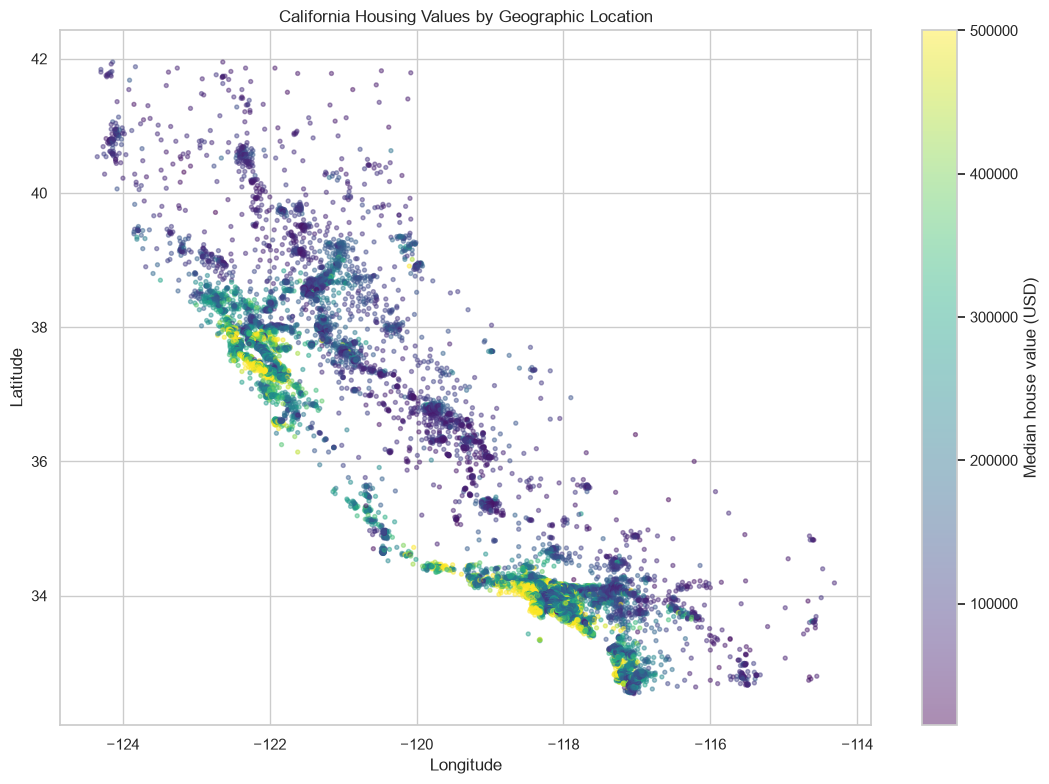

In [12]:
plt.figure(figsize=(11, 8))
scatter = plt.scatter(
    df["longitude"], df["latitude"],
    c=df[TARGET], cmap="viridis", s=8, alpha=0.45
)
plt.colorbar(scatter, label="Median house value (USD)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("California Housing Values by Geographic Location")
plt.tight_layout()
plt.show()


The map shows spatial structure in house values, with higher-valued areas clustering near parts of the coast and metropolitan regions. This supports retaining longitude, latitude, and ocean proximity, while also warning that random train/test splits may place geographically similar districts in both partitions.


### 5.4 Correlation heatmap

Pearson correlation measures linear association between numeric variables. Values close to +1 or -1 indicate stronger linear association; values near 0 indicate weaker linear association. Correlation is not proof of causation. We use this heatmap as an initial screen for potential multicollinearity and relationships with the target.


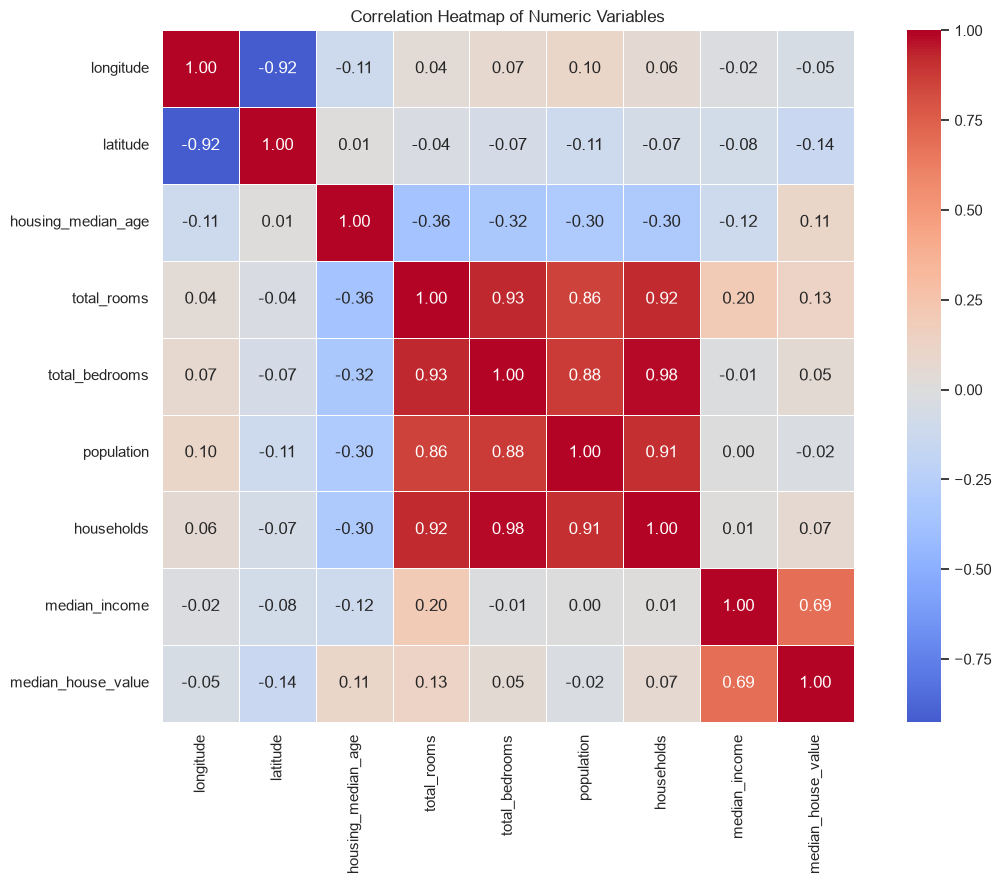

Numeric features ranked by absolute correlation with the target:


,correlation_with_target
median_income,0.688
latitude,-0.144
total_rooms,0.134
housing_median_age,0.106
households,0.066
total_bedrooms,0.050
longitude,-0.046
population,-0.025


In [13]:
correlation_matrix = df.select_dtypes(include=np.number).corr()

plt.figure(figsize=(12, 9))
sns.heatmap(
    correlation_matrix, annot=True, fmt=".2f",
    cmap="coolwarm", center=0, square=True,
    linewidths=0.5
)
plt.title("Correlation Heatmap of Numeric Variables")
plt.tight_layout()
plt.show()

target_correlations = correlation_matrix[TARGET].drop(TARGET).sort_values(
    key=lambda values: values.abs(), ascending=False
)
print("Numeric features ranked by absolute correlation with the target:")
display(target_correlations.to_frame("correlation_with_target"))


Median income has the strongest linear association with the target among the numeric features; most individual room and population counts have much weaker correlations. Correlation is a marginal linear measure and does not capture nonlinear effects or interactions. **Observed result:** median-income correlation is 0.688; the next-largest absolute numeric correlation is latitude at -0.144.


### 5.5 Categorical feature

`ocean_proximity` is categorical. We inspect its categories and the median target value within each group. The model will later encode this column using one-hot encoding rather than assigning arbitrary numeric ranks.


,district_count
ocean_proximity,
<1H OCEAN,9136
INLAND,6551
NEAR OCEAN,2658
NEAR BAY,2290
ISLAND,5


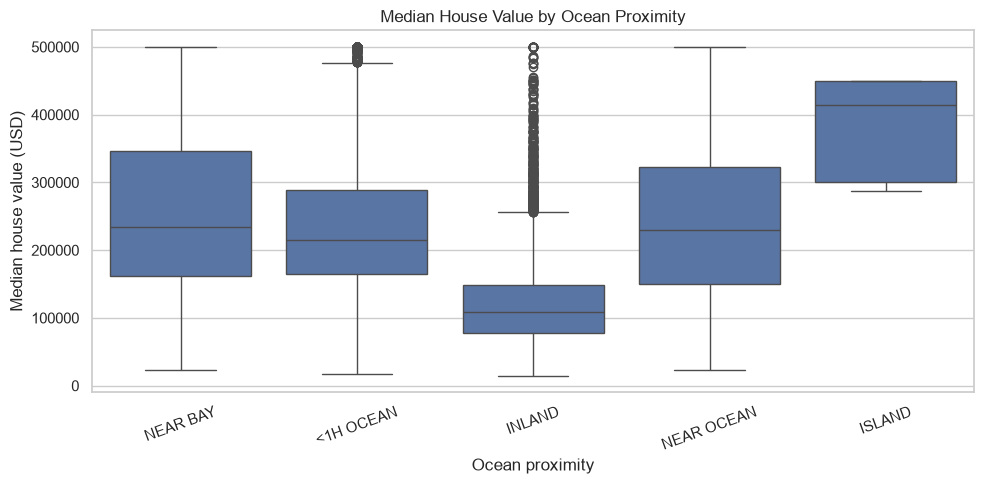

,count,mean,median
ocean_proximity,,,
ISLAND,5,"380,440.000","414,700.000"
NEAR BAY,2290,"259,212.312","233,800.000"
NEAR OCEAN,2658,"249,433.977","229,450.000"
<1H OCEAN,9136,"240,084.285","214,850.000"
INLAND,6551,"124,805.392","108,500.000"


In [14]:
display(df["ocean_proximity"].value_counts(dropna=False).to_frame("district_count"))

plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x="ocean_proximity", y=TARGET)
plt.title("Median House Value by Ocean Proximity")
plt.xlabel("Ocean proximity")
plt.ylabel("Median house value (USD)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

display(
    df.groupby("ocean_proximity", dropna=False)[TARGET]
      .agg(["count", "mean", "median"])
      .sort_values("median", ascending=False)
)


The category counts are imbalanced, and the boxplot/table compare price distributions by location group. The median for inland districts is much lower than coastal categories. The Island group contains only five rows, so its high median is based on a very small sample and is not a stable estimate. **Observed result:** `<1H OCEAN` has 9,136 districts, `INLAND` 6,551, `NEAR OCEAN` 2,658, `NEAR BAY` 2,290, and `ISLAND` 5. The inland median is $108,500; the island median is $414,700.


## 7. Train/test split

We separate the target from the predictors and create a held-out test set. The test set is not used to fit imputers, scalers, encoders or tune alpha values. A 80/20 split is used. We use the same split for all models to make the comparison fair.


In [15]:
X = df.drop(columns=[TARGET]).copy()
y = df[TARGET].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

print("Training predictors:", X_train.shape)
print("Test predictors:", X_test.shape)
print("Training target:", y_train.shape)
print("Test target:", y_test.shape)


Training predictors: (16512, 9)
Test predictors: (4128, 9)
Training target: (16512,)
Test target: (4128,)


The target is separated from predictors and a reproducible 80/20 hold-out is created. This split is used for one final comparison after training-only cross-validation and model tuning. **Observed result:** 16,512 training rows and 4,128 test rows, each with nine original predictors.


## 8. Feature engineering

We create interpretable ratio and interaction features:

- `rooms_per_household`: average rooms per household.
- `bedrooms_per_room`: proportion of rooms that are bedrooms.
- `population_per_household`: average population per household.
- `income_x_rooms_per_household`: an interaction between median income and rooms per household.
- `latitude_x_longitude`: a simple geographic interaction.

Ratios are calculated safely to avoid division by zero. These transformations are deterministic and do not learn from the target. They are placed inside the modelling pipeline so the same transformations are applied consistently to training and test data.

The shared `add_engineered_features` function is defined in `housing_features.py`, allowing the saved model pipeline to be loaded from Python outside the notebook. The helper uses only row-level feature calculations and does not learn from the target.


In [16]:
# The feature function lives in housing_features.py so saved models can be reloaded outside this notebook.
X_train_engineered_preview = add_engineered_features(X_train)
new_features = [
    "rooms_per_household", "bedrooms_per_room",
    "population_per_household", "income_x_rooms_per_household",
    "latitude_x_longitude"
]
display(X_train_engineered_preview[new_features].describe().T)


,count,mean,std,min,25%,50%,75%,max
rooms_per_household,"16,512.000",5.435,2.387,0.889,4.452,5.236,6.061,141.909
bedrooms_per_room,"16,512.000",0.213,0.058,0.100,0.175,0.203,0.240,1.000
population_per_household,"16,512.000",3.097,11.579,0.692,2.429,2.817,3.280,"1,243.333"
income_x_rooms_per_household,"16,512.000",22.620,17.555,0.857,11.709,18.098,28.014,333.336
latitude_x_longitude,"16,512.000","-4,266.251",324.080,"-5,207.673","-4,601.572","-4,062.149","-4,004.363","-3,757.240"


The function creates ratios and interactions that can express household composition and combined income/room effects. Safe division turns zero denominators into missing values for later imputation. Some ratios have extreme values, so their impact is handled by model choice and the downstream diagnostics rather than assumed harmless.


## 9. Multicollinearity diagnostics

Multicollinearity occurs when predictors contain overlapping information. It can make ordinary least-squares coefficients unstable and difficult to interpret. Ridge and Lasso are useful regularisation approaches, although they do not make every correlated feature problem disappear. We first inspect the correlation matrix of engineered numeric training features. We also calculate Variance Inflation Factor (VIF) when `statsmodels` is installed. VIF is calculated on the training predictors only, after median imputation for this diagnostic. Very large VIF values can indicate redundancy; interpret them alongside domain knowledge and the correlation heatmap.


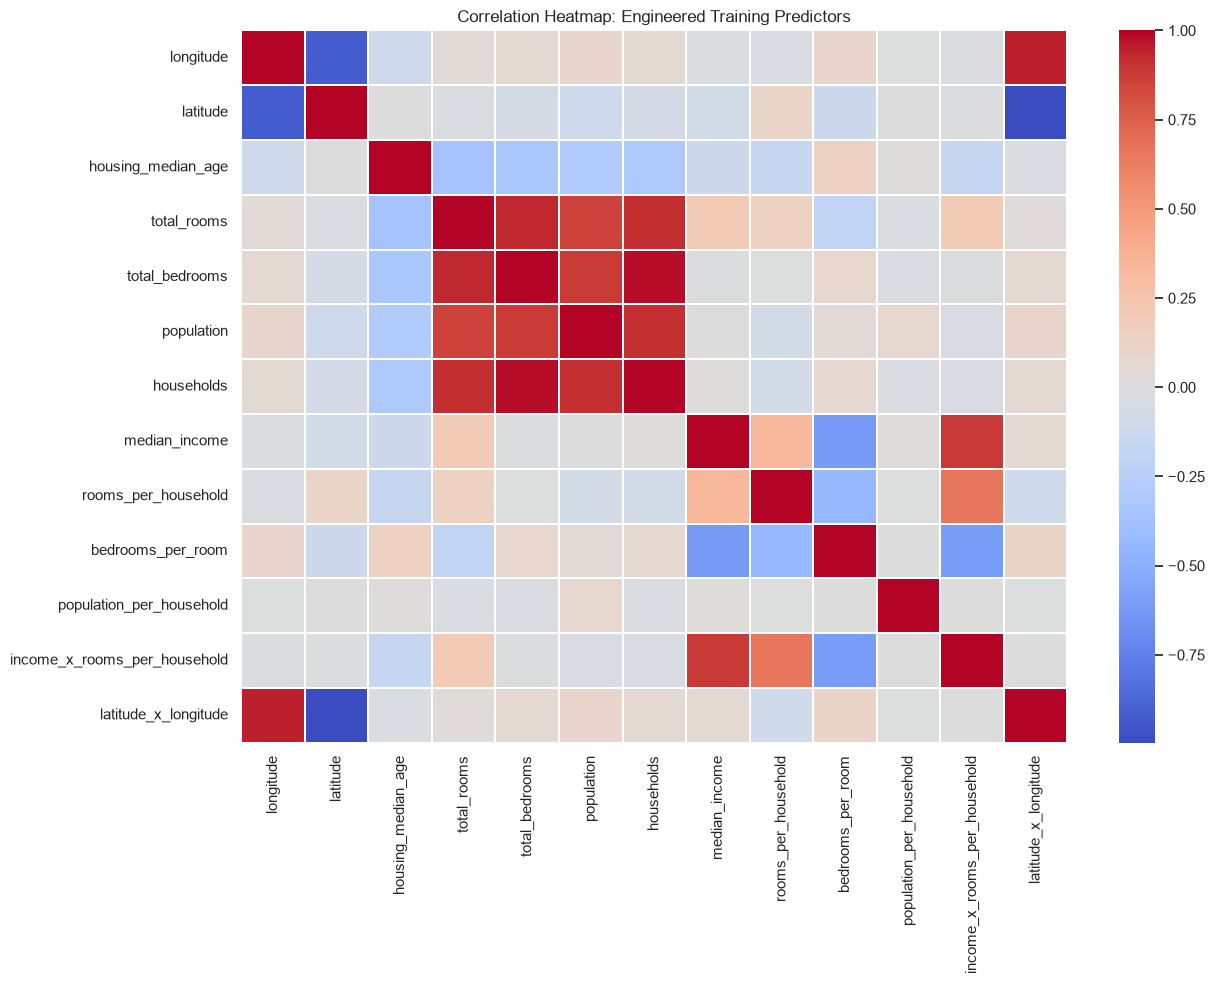

,feature,VIF
12,latitude_x_longitude,"13,243.048"
1,latitude,"8,339.793"
0,longitude,649.174
4,total_bedrooms,49.938
6,households,47.028
3,total_rooms,18.840
11,income_x_rooms_per_household,17.801
7,median_income,13.700
5,population,6.905
8,rooms_per_household,4.510


In [17]:
X_train_engineered = add_engineered_features(X_train)
numeric_engineered_columns = X_train_engineered.select_dtypes(include=np.number).columns.tolist()

# Median-impute only for this diagnostic calculation.
diagnostic_numeric = X_train_engineered[numeric_engineered_columns].copy()
diagnostic_numeric = diagnostic_numeric.replace([np.inf, -np.inf], np.nan)
diagnostic_numeric = diagnostic_numeric.fillna(diagnostic_numeric.median())

plt.figure(figsize=(13, 10))
sns.heatmap(
    diagnostic_numeric.corr(), cmap="coolwarm", center=0,
    annot=False, linewidths=0.25
)
plt.title("Correlation Heatmap: Engineered Training Predictors")
plt.tight_layout()
plt.show()

try:
    from statsmodels.stats.outliers_influence import variance_inflation_factor

    # Remove constant columns before VIF calculation.
    vif_input = diagnostic_numeric.loc[:, diagnostic_numeric.nunique() > 1].copy()
    vif_values = []
    for index, column in enumerate(vif_input.columns):
        vif_values.append(variance_inflation_factor(vif_input.values, index))

    vif_table = pd.DataFrame({
        "feature": vif_input.columns,
        "VIF": vif_values
    }).sort_values("VIF", ascending=False)
    display(vif_table)
except ImportError:
    print("statsmodels is not installed; skipping VIF. Install with:")
    print("python3 -m pip install statsmodels")
except Exception as error:
    print("VIF calculation could not be completed:", error)
    print("Use the correlation heatmap as the multicollinearity diagnostic.")


The correlation heatmap and VIF table are computed from training predictors only. Several derived geographic and count features are strongly collinear; this can make unregularized linear coefficients unstable. Regularization is included for comparison, while the nonlinear benchmark is less dependent on linear coefficient assumptions. **Observed result:** VIF is especially high for `latitude_x_longitude` (about 13,243), `latitude` (about 8,340), and `longitude` (about 649).


## 10. Build the preprocessing pipeline

A `ColumnTransformer` applies different preprocessing to numeric and categorical columns:

**Numeric pipeline**

1. Replace missing values with the training median.
2. Standardise features using `StandardScaler`.

**Categorical pipeline**

1. Replace missing values with the most frequent category.
2. One-hot encode categories.

Standardisation is especially important for Ridge and Lasso because their penalty is sensitive to coefficient scale. We keep preprocessing inside the scikit-learn `Pipeline`, ensuring that each cross-validation fold learns its own imputation, scaling and encoding parameters.

The helper below supports both newer and older scikit-learn versions (`sparse_output` versus `sparse`).


In [18]:
# Feature engineering step; feature names are preserved where supported.
feature_engineering = FunctionTransformer(
    add_engineered_features,
    validate=False
)

numeric_features = numeric_columns = X_train.select_dtypes(include=np.number).columns.tolist()
engineered_numeric_features = numeric_features + new_features
categorical_features = X_train.select_dtypes(exclude=np.number).columns.tolist()

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Support both current and older scikit-learn releases.
try:
    one_hot_encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=True)
except TypeError:
    one_hot_encoder = OneHotEncoder(handle_unknown="ignore", sparse=True)

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", one_hot_encoder)
])

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_transformer, engineered_numeric_features),
        ("categorical", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

print("Numeric features including engineered features:", len(engineered_numeric_features))
print("Categorical features:", categorical_features)


Numeric features including engineered features: 13
Categorical features: ['ocean_proximity']


After feature engineering, the pipeline contains 13 numeric features and one categorical predictor. Numeric values are imputed and standardized, and ocean categories are one-hot encoded. Because these operations are part of the estimator pipeline, each cross-validation fold fits preprocessing only on its training data.


## 11. Define OLS, Ridge, Lasso and XGBoost models

OLS provides a baseline with no coefficient penalty. Ridge adds an L2 penalty that shrinks coefficients towards zero. Lasso adds an L1 penalty and can set some coefficients exactly to zero.

We use the same feature engineering and preprocessing steps for all three algorithms.


In [19]:
def make_model_pipeline(regressor):
    return Pipeline(steps=[
        ("feature_engineering", feature_engineering),
        ("preprocessor", preprocessor),
        ("regressor", regressor)
    ])

ols_model = make_model_pipeline(LinearRegression())
ridge_pipeline = make_model_pipeline(Ridge())
lasso_pipeline = make_model_pipeline(Lasso(max_iter=20000, tol=1e-4))

print("OLS, Ridge and Lasso pipelines are ready.")


OLS, Ridge and Lasso pipelines are ready.


The notebook builds comparable OLS, Ridge, and Lasso pipelines using the same feature engineering and preprocessing. Ridge and Lasso add regularization; the subsequent tuning cell also defines XGBoost as a nonlinear performance benchmark while retaining all required linear models. **Observed result:** the three linear pipelines were constructed successfully.


## 12. Fit the OLS baseline

We fit OLS on the training data and calculate its test metrics. This establishes a baseline against which tuned Ridge and Lasso models can be compared.


In [20]:
ols_model.fit(X_train, y_train)
ols_predictions = ols_model.predict(X_test)

def regression_metrics(y_true, y_pred):
    """Return commonly used regression metrics."""
    return {
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAE": mean_absolute_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred)
    }

ols_metrics = regression_metrics(y_test, ols_predictions)
display(pd.DataFrame([ols_metrics], index=["OLS"]))


,RMSE,MAE,R2
OLS,"68,598.398","49,442.689",0.641


OLS is fit only on the training partition and establishes the reference error before regularization or nonlinear modeling. RMSE penalizes large errors more heavily, MAE gives the typical absolute dollar error, and R² describes variance explained on this test split. **Observed result:** test RMSE is $68,598.40, MAE is $49,442.69, and R² is 0.6409.


## 13. Tune Ridge, Lasso and XGBoost using training-only cross-validation

`alpha` controls the strength of regularisation. A larger alpha means a stronger penalty. We search a logarithmic grid of alpha values. Five-fold cross-validation is performed on the training set, using negative RMSE as the scoring metric. GridSearchCV maximises the score, so the negative sign is used because lower RMSE is better. The held-out test set is not used during tuning.


In [21]:
from sklearn.compose import TransformedTargetRegressor

# Increase Lasso's iteration limit. Avoid near-zero alpha values that are numerically unstable and add little beyond the OLS baseline.
lasso_pipeline.set_params(
    regressor__max_iter=100000,
    regressor__tol=1e-4
)

# Standardise targets during training; predictions are converted back to dollars.
ridge_model = TransformedTargetRegressor(
    regressor=ridge_pipeline,
    transformer=StandardScaler()
)

lasso_model = TransformedTargetRegressor(
    regressor=lasso_pipeline,
    transformer=StandardScaler()
)

alpha_grid = np.logspace(-4, 2, 13)
cv_strategy = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

ridge_search = GridSearchCV(
    estimator=ridge_model,
    param_grid={"regressor__regressor__alpha": alpha_grid},
    scoring="neg_root_mean_squared_error",
    cv=cv_strategy,
    n_jobs=-1,
    refit=True,
    return_train_score=True
)

lasso_search = GridSearchCV(
    estimator=lasso_model,
    param_grid={"regressor__regressor__alpha": alpha_grid},
    scoring="neg_root_mean_squared_error",
    cv=cv_strategy,
    n_jobs=-1,
    refit=True,
    return_train_score=True
)

# A nonlinear tree booster can model interactions and geographic/nonlinear patterns
# that OLS, Ridge and Lasso cannot represent without additional transforms.
xgb_pipeline = make_model_pipeline(XGBRegressor(
    objective="reg:squarederror",
    tree_method="hist",
    random_state=RANDOM_STATE,
    n_jobs=2
))
xgb_search_space = {
    "regressor__n_estimators": [400, 600, 800, 1000],
    "regressor__max_depth": [3, 4, 5, 6],
    "regressor__learning_rate": [0.025, 0.04, 0.06, 0.08],
    "regressor__subsample": [0.7, 0.85, 1.0],
    "regressor__colsample_bytree": [0.7, 0.85, 1.0],
    "regressor__min_child_weight": [1, 3, 5],
    "regressor__reg_lambda": [2, 5, 10]
}
xgb_search = RandomizedSearchCV(
    estimator=xgb_pipeline,
    param_distributions=xgb_search_space,
    n_iter=16,
    scoring="neg_root_mean_squared_error",
    cv=cv_strategy,
    random_state=RANDOM_STATE,
    n_jobs=1,
    refit=True,
    verbose=0
)

# OLS has no regularisation parameter; estimate its training CV RMSE for fair selection.
ols_cv_rmse = -cross_val_score(
    ols_model, X_train, y_train,
    cv=cv_strategy,
    scoring="neg_root_mean_squared_error",
    n_jobs=1
).mean()

print("Tuning Ridge...")
ridge_search.fit(X_train, y_train)
print("Tuning Lasso...")
lasso_search.fit(X_train, y_train)
print("Tuning XGBoost...")
xgb_search.fit(X_train, y_train)

cv_rmse_by_model = {
    "OLS": ols_cv_rmse,
    "Ridge": -ridge_search.best_score_,
    "Lasso": -lasso_search.best_score_,
    "XGBoost": -xgb_search.best_score_
}
print("\nBest Ridge alpha:", ridge_search.best_params_["regressor__regressor__alpha"])
print("Best Ridge CV RMSE:", round(cv_rmse_by_model["Ridge"], 2))
print("Best Lasso alpha:", lasso_search.best_params_["regressor__regressor__alpha"])
print("Best Lasso CV RMSE:", round(cv_rmse_by_model["Lasso"], 2))
print("Best XGBoost CV RMSE:", round(cv_rmse_by_model["XGBoost"], 2))
print("Best XGBoost parameters:", xgb_search.best_params_)


Tuning Ridge...


Tuning Lasso...


Tuning XGBoost...



Best Ridge alpha: 0.0001
Best Ridge CV RMSE: 67534.42
Best Lasso alpha: 0.0001
Best Lasso CV RMSE: 67606.95
Best XGBoost CV RMSE: 44486.68
Best XGBoost parameters: {'regressor__subsample': 1.0, 'regressor__reg_lambda': 2, 'regressor__n_estimators': 1000, 'regressor__min_child_weight': 3, 'regressor__max_depth': 6, 'regressor__learning_rate': 0.08, 'regressor__colsample_bytree': 0.7}


Ridge and Lasso are tuned over a range of alpha values using five-fold training CV. XGBoost is tuned over tree depth, learning rate, sampling, regularization, and estimator count using the same training-only CV strategy. The final model is selected by CV RMSE, not by inspecting test scores. **Observed result:** Ridge and Lasso both selected alpha 0.0001, with CV RMSE $67,534.42 and $67,606.95. XGBoost achieved CV RMSE $44,486.68 and selected 1,000 trees, depth 6, learning rate 0.08, subsample 1.0, column subsampling 0.7, and regularization 2.


## 14. Evaluate all models on the held-out test set

We evaluate the fitted OLS baseline and the best Ridge and Lasso estimators on exactly the same test observations. This gives a fair comparison.

Metric interpretation:

- **RMSE:** typical error magnitude with extra sensitivity to large errors; measured in dollars.
- **MAE:** average absolute prediction error; measured in dollars.
- **R²:** proportion of test-target variance explained by the model. Higher is generally better; it can be negative if the model performs worse than predicting the test mean.


In [22]:
best_ridge = ridge_search.best_estimator_
best_lasso = lasso_search.best_estimator_
best_xgb = xgb_search.best_estimator_

predictions = {
    "OLS": ols_predictions,
    "Ridge": best_ridge.predict(X_test),
    "Lasso": best_lasso.predict(X_test),
    "XGBoost": best_xgb.predict(X_test)
}

metrics_table = pd.DataFrame({
    model_name: regression_metrics(y_test, model_predictions)
    for model_name, model_predictions in predictions.items()
}).T
metrics_table["CV RMSE"] = pd.Series(cv_rmse_by_model)
metrics_table = metrics_table.sort_values("CV RMSE")
display(metrics_table.style.format({
    "RMSE": "${:,.2f}",
    "MAE": "${:,.2f}",
    "R2": "{:.4f}",
    "CV RMSE": "${:,.2f}"
}))

best_model_name = metrics_table.index[0]
final_model = {
    "OLS": ols_model,
    "Ridge": best_ridge,
    "Lasso": best_lasso,
    "XGBoost": best_xgb
}[best_model_name]
print(f"Model selected by training CV RMSE: {best_model_name}")


,RMSE,MAE,R2,CV RMSE
XGBoost,"$42,827.42","$27,715.81",0.8600,"$44,486.68"
OLS,"$68,598.40","$49,442.69",0.6409,"$67,534.42"
Ridge,"$68,598.41","$49,442.70",0.6409,"$67,534.42"
Lasso,"$68,736.68","$49,546.47",0.6394,"$67,606.95"


Model selected by training CV RMSE: XGBoost


All four models are evaluated on the same held-out test rows. The displayed RMSE, MAE, and R² are test metrics; the separate CV RMSE column is used to choose the model without test-set selection. **Observed result:** XGBoost has the lowest training CV RMSE and the strongest test metrics: RMSE $42,827.42, MAE $27,715.81, R² 0.8600. OLS and Ridge are nearly identical (RMSE about $68,598; R² 0.6409), while Lasso is slightly worse. XGBoost is selected by CV RMSE.


## 15. Compare cross-validation results across alpha values

These plots show how the average cross-validation RMSE changes with alpha for Ridge and Lasso. The selected alpha is the value with the lowest cross-validation RMSE in the tested grid.


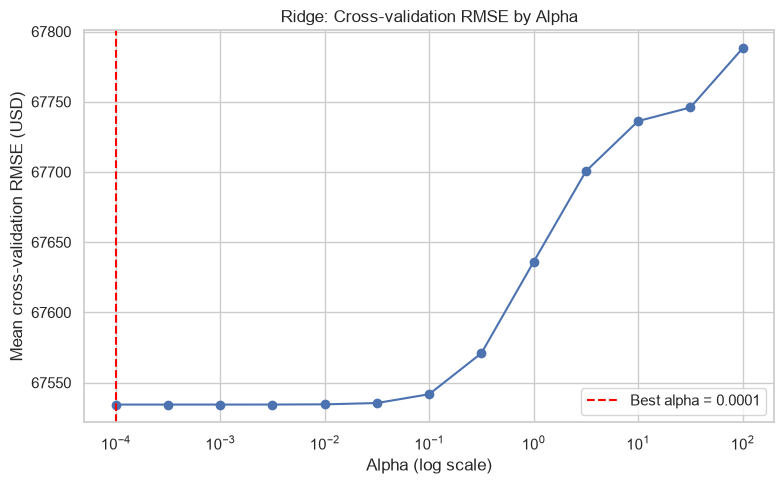

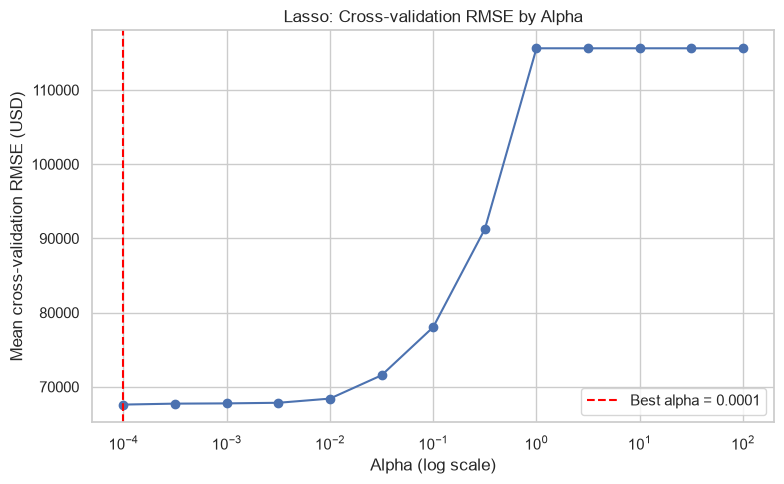

In [23]:
def plot_grid_search(search, model_label):
    results = pd.DataFrame(search.cv_results_)
    results["alpha"] = results["param_regressor__regressor__alpha"].astype(float)
    results["mean_cv_rmse"] = -results["mean_test_score"]

    plt.figure(figsize=(8, 5))
    plt.semilogx(results["alpha"], results["mean_cv_rmse"], marker="o")
    plt.axvline(
        search.best_params_["regressor__regressor__alpha"],
        color="red", linestyle="--",
        label=f"Best alpha = {search.best_params_['regressor__regressor__alpha']:.4g}"
    )
    plt.xlabel("Alpha (log scale)")
    plt.ylabel("Mean cross-validation RMSE (USD)")
    plt.title(f"{model_label}: Cross-validation RMSE by Alpha")
    plt.legend()
    plt.tight_layout()
    plt.show()

plot_grid_search(ridge_search, "Ridge")
plot_grid_search(lasso_search, "Lasso")


The two plots show how five-fold training RMSE changes with alpha for Ridge and Lasso. The selected alpha is at the low end of the tested range, indicating that strong shrinkage did not improve this engineered linear feature set. Near-zero regularization explains why OLS and Ridge perform almost identically.


## 16. Actual versus predicted values

A strong model should place predictions reasonably close to the 45-degree reference line. Systematic deviations can indicate bias, nonlinear patterns or difficulty predicting particular price ranges.


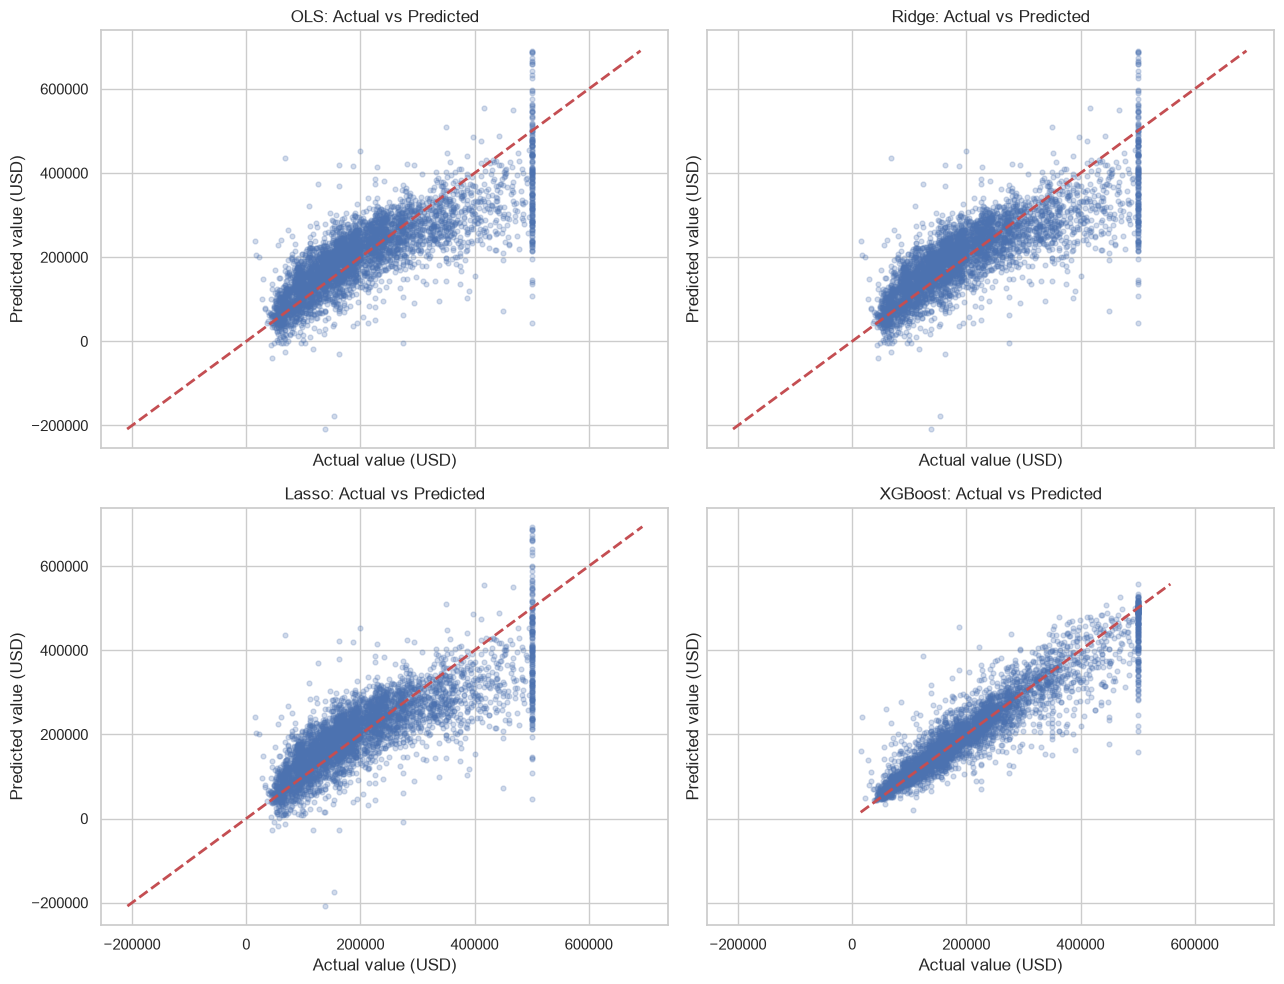

In [24]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10), sharex=True, sharey=True)
for ax, (model_name, model_predictions) in zip(axes.flat, predictions.items()):
    ax.scatter(y_test, model_predictions, alpha=0.25, s=12)
    lower = min(y_test.min(), model_predictions.min())
    upper = max(y_test.max(), model_predictions.max())
    ax.plot([lower, upper], [lower, upper], "r--", linewidth=2)
    ax.set_title(f"{model_name}: Actual vs Predicted")
    ax.set_xlabel("Actual value (USD)")
    ax.set_ylabel("Predicted value (USD)")

plt.tight_layout()
plt.show()


Each panel compares test predictions with the ideal 45-degree line. XGBoost predictions follow the line more closely across a broader range of values than the linear models, consistent with its lower test RMSE. Errors remain larger in some price ranges, especially near the target ceiling.


## 17. Residual analysis

A residual is the observed target minus the model prediction:

**Residual = Actual value − Predicted value**

- Positive residual: the model underpredicted the house value.
- Negative residual: the model overpredicted the house value.
- Residuals randomly scattered around zero are generally desirable.
- A funnel shape can indicate non-constant error variance (heteroscedasticity).
- Curvature can indicate a missing nonlinear relationship.

We inspect residuals against fitted values and their distributions for all three models.


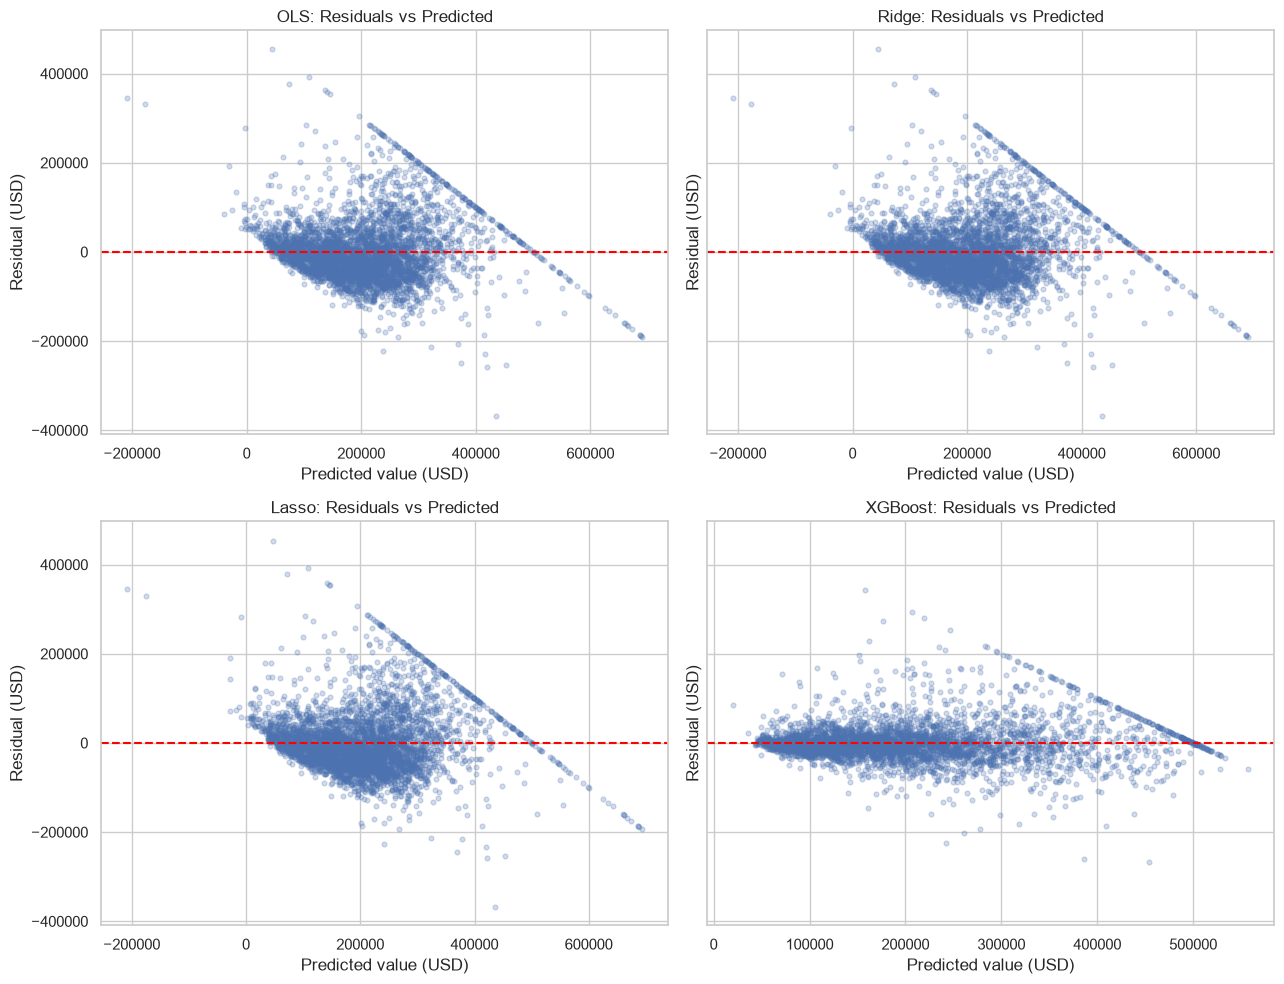

In [25]:
residuals = {
    model_name: y_test.to_numpy() - model_predictions
    for model_name, model_predictions in predictions.items()
}

fig, axes = plt.subplots(2, 2, figsize=(13, 10), sharey=True)
for ax, (model_name, model_predictions) in zip(axes.flat, predictions.items()):
    ax.scatter(model_predictions, residuals[model_name], alpha=0.25, s=12)
    ax.axhline(0, color="red", linestyle="--")
    ax.set_title(f"{model_name}: Residuals vs Predicted")
    ax.set_xlabel("Predicted value (USD)")
    ax.set_ylabel("Residual (USD)")

plt.tight_layout()
plt.show()


Residuals are actual minus predicted values, so positive values indicate underprediction and negative values indicate overprediction. The plots help reveal nonconstant error spread and systematic patterns; XGBoost has a narrower residual range overall, though it does not eliminate all errors or target-ceiling effects.


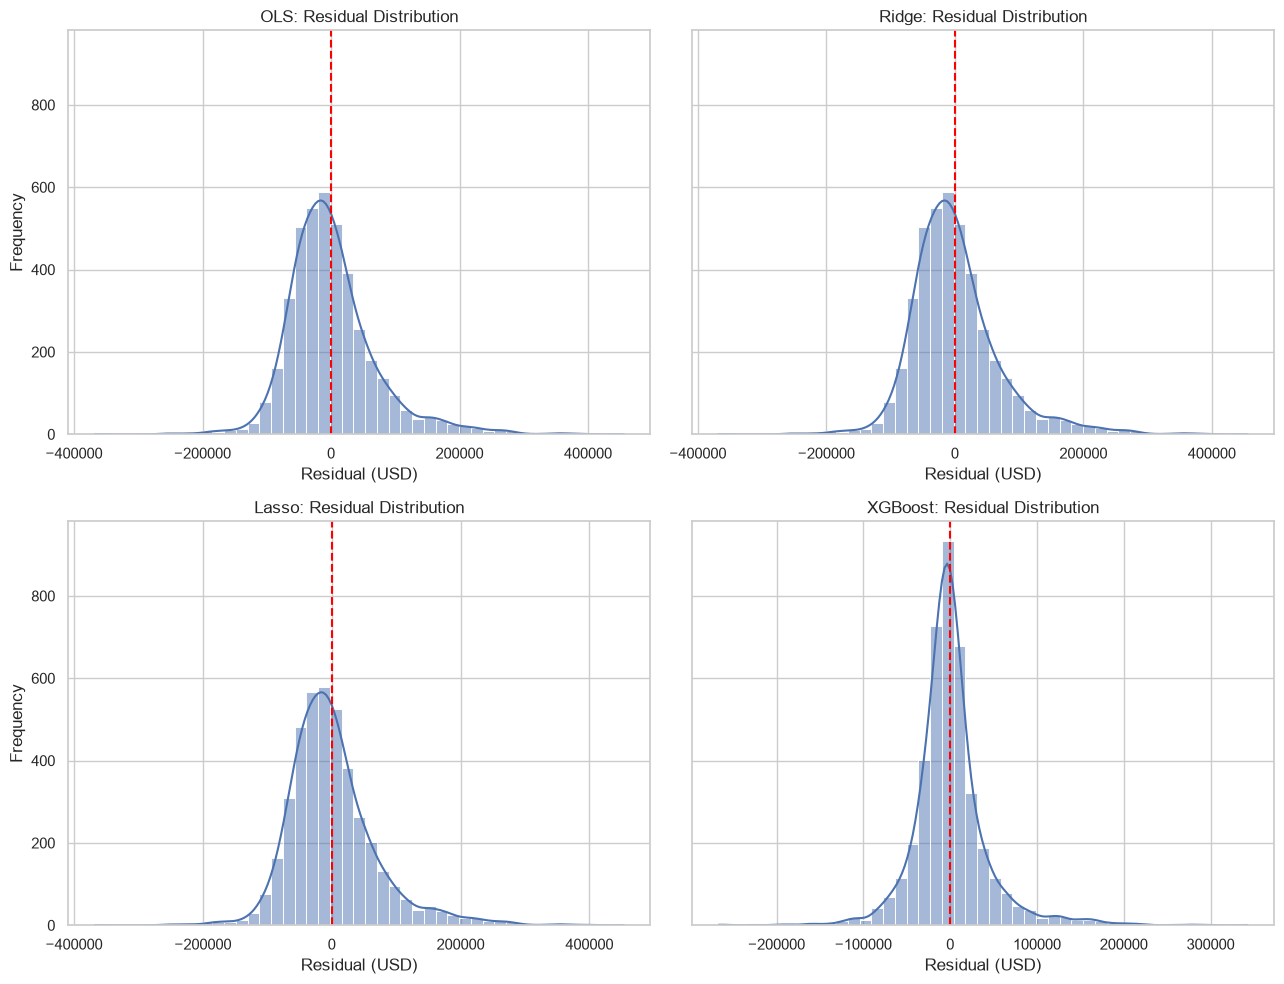

In [26]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10), sharey=True)
for ax, (model_name, model_residuals) in zip(axes.flat, residuals.items()):
    sns.histplot(model_residuals, bins=45, kde=True, ax=ax)
    ax.axvline(0, color="red", linestyle="--")
    ax.set_title(f"{model_name}: Residual Distribution")
    ax.set_xlabel("Residual (USD)")
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()


These histograms show the spread and skew of each model's test residuals around zero. A narrow distribution is preferable, but tails and asymmetry indicate that some districts are difficult to predict. XGBoost has visibly less spread than the linear models.


## 18. Residual summary

The following table provides the mean and standard deviation of residuals. A residual mean close to zero is desirable, although the shape and spread of residuals also matter.


In [27]:
residual_summary = pd.DataFrame({
    name: {
        "mean_residual": np.mean(values),
        "std_residual": np.std(values, ddof=1),
        "minimum_residual": np.min(values),
        "maximum_residual": np.max(values)
    }
    for name, values in residuals.items()
}).T

display(residual_summary.style.format("{:,.2f}"))


,mean_residual,std_residual,minimum_residual,maximum_residual
OLS,855.36,"68,601.37","-367,602.56","455,561.79"
Ridge,855.37,"68,601.39","-367,602.79","455,561.10"
Lasso,879.86,"68,739.37","-367,761.88","453,255.76"
XGBoost,231.74,"42,831.98","-266,679.41","342,598.30"


The residual means are close to zero, suggesting little overall signed bias on this test split. Residual standard deviation is substantially lower for XGBoost, matching its lower RMSE. **Observed result:** XGBoost residual mean is about $232 and standard deviation about $42,832; linear-model residual standard deviations are about $68,600-$68,739. The large minimum/maximum residuals show that individual errors can still be substantial.


## 19. Inspect Lasso coefficients and feature selection

Lasso can shrink some coefficients exactly to zero. We extract the transformed feature names and coefficients to see which variables remain in the selected model A non-zero coefficient is not proof of causality or independent importance. Correlated predictors can share or compete for coefficient weight.


In [28]:
lasso_pipeline_fitted = best_lasso.regressor_
lasso_preprocessor = lasso_pipeline_fitted.named_steps["preprocessor"]
lasso_regressor = lasso_pipeline_fitted.named_steps["regressor"]

try:
    transformed_feature_names = lasso_preprocessor.get_feature_names_out()
    coefficient_table = pd.DataFrame({
        "feature": transformed_feature_names,
        "coefficient": lasso_regressor.coef_
    })
    coefficient_table["absolute_coefficient"] = coefficient_table["coefficient"].abs()
    coefficient_table = coefficient_table.sort_values(
        "absolute_coefficient", ascending=False
    )

    display(coefficient_table.head(20))
    nonzero_count = np.count_nonzero(lasso_regressor.coef_)
    zero_count = len(lasso_regressor.coef_) - nonzero_count
    print(f"Non-zero coefficients: {nonzero_count}")
    print(f"Zero coefficients: {zero_count}")
except Exception as error:
    print("Could not extract feature names:", error)


,feature,coefficient,absolute_coefficient
12,numeric__latitude_x_longitude,2.828,2.828
1,numeric__latitude,1.792,1.792
0,numeric__longitude,-1.071,1.071
7,numeric__median_income,0.789,0.789
15,categorical__ocean_proximity_ISLAND,0.732,0.732
5,numeric__population,-0.394,0.394
14,categorical__ocean_proximity_INLAND,-0.321,0.321
6,numeric__households,0.312,0.312
9,numeric__bedrooms_per_room,0.154,0.154
11,numeric__income_x_rooms_per_household,-0.135,0.135


Non-zero coefficients: 17
Zero coefficients: 1


The coefficient table is based on standardized features and a standardized target, so coefficient magnitudes are not dollar effects. Lasso leaves 17 of 18 transformed coefficients nonzero and sets one to zero, meaning this tuned alpha provides very little feature selection. These coefficients describe the linear model and should not be read as causal effects. **Observed result:** latitude/longitude interaction and coordinates have the largest absolute coefficients, followed by median income and the Island category.


## 20. Optional interactive dashboard

If Plotly is installed, this section creates an interactive chart for the model comparison. Plotly is optional; the static Matplotlib and Seaborn plots above are the required visual outputs.


In [29]:
try:
    import plotly.express as px

    interactive_metrics = metrics_table.reset_index(names="Model")
    fig = px.bar(
        interactive_metrics,
        x="Model", y=["RMSE", "MAE"],
        barmode="group",
        title="Interactive Model Error Comparison (USD)",
        labels={"value": "Error (USD)", "variable": "Metric"}
    )
    fig.show()

    fig_r2 = px.bar(
        interactive_metrics,
        x="Model", y="R2",
        title="Interactive Test R² Comparison",
        labels={"R2": "R²"}
    )
    fig_r2.show()

except ImportError:
    print("Plotly is not installed. Optional installation: python3 -m pip install plotly")


When Plotly is available, this cell creates interactive bar charts for the models' test RMSE/MAE and R². These repeat the static comparison in a form that can be explored interactively; the notebook completed without an optional-dependency error.


## 21. Optional permutation importance

Permutation importance measures how much a fitted model's score decreases when one input column is randomly shuffled. It is model-agnostic and calculated on the held-out test set here, so treat it as a descriptive diagnostic rather than a causal explanation. Because the pipeline accepts the original input columns, permutation importance is calculated on the original columns (the engineered variables are generated inside the pipeline).


,feature,importance_mean,importance_std
1,latitude,"88,285.017","1,156.121"
0,longitude,"86,675.296",639.438
3,total_rooms,"64,459.685",131.996
4,total_bedrooms,"32,433.492",471.997
7,median_income,"29,430.472",577.804
5,population,"20,297.206",588.050
6,households,"18,382.560",567.165
8,ocean_proximity,"15,270.682",327.534
2,housing_median_age,"5,185.575",395.742


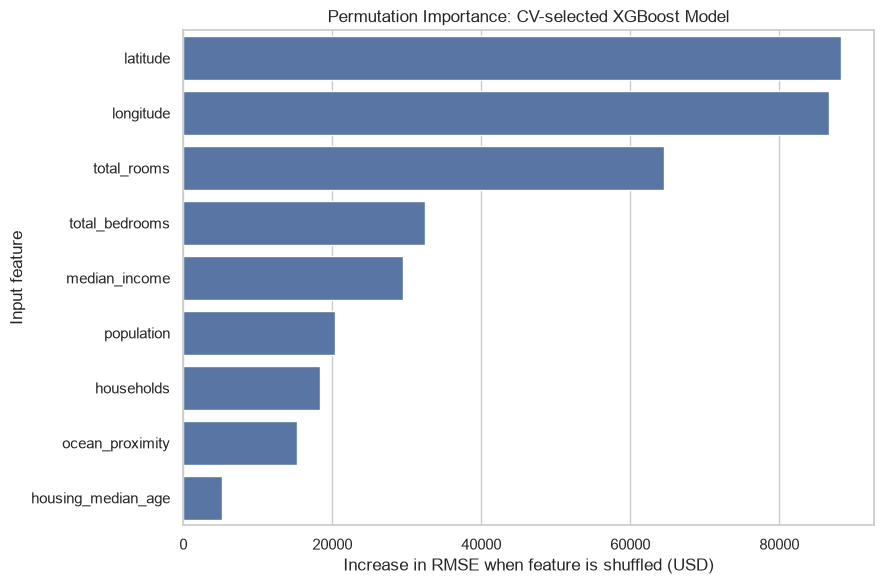

In [30]:
importance_result = permutation_importance(
    final_model, X_test, y_test,
    n_repeats=5,
    random_state=RANDOM_STATE,
    scoring="neg_root_mean_squared_error",
    n_jobs=1
)

importance_table = pd.DataFrame({
    "feature": X_test.columns,
    "importance_mean": importance_result.importances_mean,
    "importance_std": importance_result.importances_std
}).sort_values("importance_mean", ascending=False)

display(importance_table)

plt.figure(figsize=(9, 6))
sns.barplot(
    data=importance_table.head(12),
    x="importance_mean", y="feature"
)
plt.title(f"Permutation Importance: CV-selected {best_model_name} Model")
plt.xlabel("Increase in RMSE when feature is shuffled (USD)")
plt.ylabel("Input feature")
plt.tight_layout()
plt.show()


Permutation importance reports the increase in RMSE when one original input feature is shuffled for the CV-selected XGBoost pipeline. Larger increases indicate greater predictive reliance in this fitted model; the result is not causal and individual importance can be shared across correlated features **Observed result:** latitude and longitude have the largest measured impact (about $88,285 and $86,675 RMSE increase), followed by total rooms, total bedrooms, and median income.


## 22. Final model comparison and project conclusion


In [31]:
print("FINAL TEST-SET MODEL COMPARISON")
display(metrics_table.style.format({
    "RMSE": "${:,.2f}",
    "MAE": "${:,.2f}",
    "R2": "{:.4f}",
    "CV RMSE": "${:,.2f}"
}))

print(f"\nSelected by training CV RMSE: {best_model_name}")
print(f"Test RMSE: ${metrics_table.loc[best_model_name, 'RMSE']:,.2f}")
print(f"Test MAE: ${metrics_table.loc[best_model_name, 'MAE']:,.2f}")
print(f"Test R2: {metrics_table.loc[best_model_name, 'R2']:.4f}")
print("\nTarget limitation: median_house_value is top-coded at $500,001 for about 4.68% of rows.")


FINAL TEST-SET MODEL COMPARISON


,RMSE,MAE,R2,CV RMSE
XGBoost,"$42,827.42","$27,715.81",0.8600,"$44,486.68"
OLS,"$68,598.40","$49,442.69",0.6409,"$67,534.42"
Ridge,"$68,598.41","$49,442.70",0.6409,"$67,534.42"
Lasso,"$68,736.68","$49,546.47",0.6394,"$67,606.95"



Selected by training CV RMSE: XGBoost
Test RMSE: $42,827.42
Test MAE: $27,715.81
Test R2: 0.8600

Target limitation: median_house_value is top-coded at $500,001 for about 4.68% of rows.


This summary reports metrics for the model selected by training CV RMSE and reminds us that the target is capped. The selected XGBoost model has test RMSE $42,827.42, MAE $27,715.81, and R² 0.8600. The cap affects about 4.68% of examples, so predictions at the upper end should be interpreted as estimates of a censored target.


## 23. Save the selected model and evaluation artefacts

This section saves the model metrics, residual summaries and predictions as CSV files so that the results can be included in the project submission. The output directory is created automatically.


In [32]:
OUTPUT_DIR = Path("outputs")
PLOTS_DIR = OUTPUT_DIR / "plots"
RESULTS_DIR = OUTPUT_DIR / "model_results"
PLOTS_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

metrics_table.to_csv(RESULTS_DIR / "Task 2_model_metrics.csv")
joblib.dump(final_model, OUTPUT_DIR / "housing_best_model.joblib")
residual_summary.to_csv(RESULTS_DIR / "Task 2_residual_summary.csv")

prediction_output = pd.DataFrame({
    "actual_house_value": y_test.to_numpy(),
    "ols_prediction": predictions["OLS"],
    "ridge_prediction": predictions["Ridge"],
    "lasso_prediction": predictions["Lasso"]
})
prediction_output.to_csv(RESULTS_DIR / "Task 2_test_set_predictions.csv", index=False)

print("Saved:")
print("-", RESULTS_DIR / "Task 2_model_metrics.csv")
print("-", RESULTS_DIR / "Task 2_residual_summary.csv")
print("-", RESULTS_DIR / "Task 2_test_set_predictions.csv")
print("-", OUTPUT_DIR / "housing_best_model.joblib")


Saved:
- outputs/model_results/Task 2_model_metrics.csv
- outputs/model_results/Task 2_residual_summary.csv
- outputs/model_results/Task 2_test_set_predictions.csv
- outputs/housing_best_model.joblib


The notebook writes the comparison metrics, residual statistics, and row-level test predictions to CSV files. It also serializes the CV-selected estimator, including its feature-engineering and preprocessing pipeline, for use on raw housing predictors. **Observed result:** all four output files were saved under `outputs/` and `outputs/model_results/`.


## Final conclusion

The notebook successfully loads and cleans the 20,640-row California Housing dataset, explores its distributions and geography, engineers ratio/interaction features, and compares the required OLS, Ridge, and Lasso models. It also adds a tuned XGBoost benchmark to capture nonlinear relationships. Preprocessing and model selection use training data and cross-validation; the held-out test set is reserved for final evaluation.

XGBoost was selected by five-fold training CV RMSE ($44,486.68). On the held-out test set it achieved **RMSE $42,827.42**, **MAE $27,715.81**, and **R² 0.8600**. Its test RMSE is about 37.6% lower than the OLS baseline ($68,598.40), while OLS and Ridge remain nearly identical and Lasso provides little shrinkage at its selected alpha. The result demonstrates a substantial improvement on this split, not a guarantee of future performance.

The target is top-coded at $500,001 for about 4.68% of rows, limiting what can be learned about more expensive districts. The random district split may also place geographically similar districts in both training and test sets; for deployment to new locations, validate with a spatial or region-based holdout.

